# Sprawozdanie — Zajęcia 2

**Przedmiot:** Uczenie głębokie w systemach rozpoznawania i przetwarzania mowy
**Zajęcia nr / temat:** 2 — Sieci rekurencyjne: budowa i uczenie
**Autor / grupa:** Adam Pastuszak / …
**Data:** …

## 1. Cel ćwiczenia

Celem było sprawdzić, jak liczba jednostek ukrytych (hidden) i długość okna wejściowego (OKNO) wpływają na prognozę kolejnej próbki szeregu czasowego

Model dostaje okno ostatnich próbek sygnału i przewiduje następną, porównałem też komórki RNN, LSTM i GRU oraz prostą heurystykę „prognoza = ostatnia próbka okna”

## 2. Metoda i implementacja

Narzędzia: Python w Google Colab, PyTorch, numpy, pandas, matplotlib

Dane: sygnał z notatnika z ćwiczenia, 2000 próbek sin(t) + 0,1·sin(3t) + szum o odchyleniu 0,05, ziarno 0, główny okres to ok. 126 próbek

Okna: wejście to OKNO kolejnych próbek, cel to następna próbka, podział chronologiczny 80/20 bez tasowania przed podziałem

Model: jedna warstwa rekurencyjna (RNN, LSTM albo GRU) i warstwa liniowa na ostatnim stanie ukrytym, funkcja straty MSE, Adam, przycinanie gradientu do normy 5

Model bazowy: RNN, hidden 32, OKNO 30, 30 epok, czyli notatnik uruchomiony bez zmian

Do funkcji trenuj dodałem zapis straty treningowej po każdej epoce (wstęp teoretyczny, część 10, krok 3), teraz zwraca dwie listy: hist (test) i hist_tr (trening)

Eksperyment A: GRU, OKNO 30, hidden 8, 16, 32 i 64

Eksperyment B: GRU, hidden 32, OKNO 10, 30, 60 i 120

Eksperyment C: hidden 32, RNN, LSTM i GRU dla OKNO 10 i 120

W każdym eksperymencie zmienia się jedna rzecz, reszta jest stała: 20 epok, lr 1e-2, batch 64

Każda konfiguracja jest trenowana 3 razy z ziarnem 0, 1 i 2 (inne wagi początkowe i kolejność paczek, dane zawsze te same), wynik to średnia i odchylenie standardowe (np.std) z np.mean(hist[-5:]), czyli średniej straty testowej z 5 ostatnich epok

Okna i podział tworzy funkcja przygotuj(okno), więc przy każdej zmianie okna są liczone od nowa

Czas treningu to średni czas jednego treningu (20 epok) na CPU

### 2.1 Instalacja i import

In [ ]:
!pip -q install torch numpy matplotlib pandas

In [2]:
import time

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

torch.manual_seed(0)
np.random.seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

EPOKI = 20
LR = 1e-2
BATCH = 64
ZIARNA = [0, 1, 2]
print("Urządzenie:", DEVICE, "| PyTorch:", torch.__version__)

Urządzenie: cpu | PyTorch: 2.14.1+cu130


### 2.2 Dane

2000 próbek, okres głównej sinusoidy: 125.6 próbek


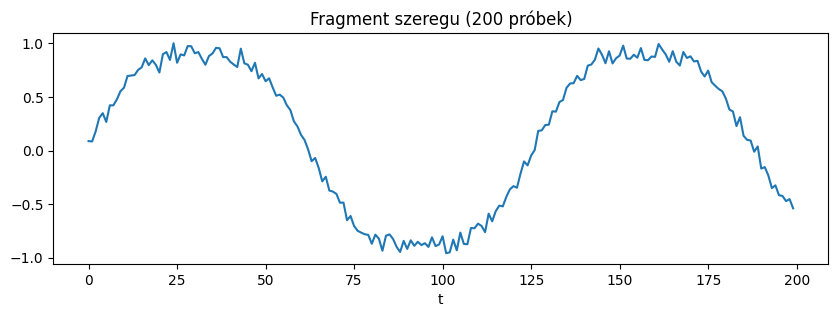

In [3]:
def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1 * np.sin(3 * t) + 0.05 * np.random.randn(n)
    return y.astype(np.float32)


seria = generuj_szereg()
okres = 2 * np.pi / (100 / (len(seria) - 1))
print(f"{len(seria)} próbek, okres głównej sinusoidy: {okres:.1f} próbek")

plt.figure(figsize=(10, 3))
plt.plot(seria[:200])
plt.title("Fragment szeregu (200 próbek)")
plt.xlabel("t")
plt.show()

### 2.3 Okna, podział i heurystyka

Dla każdego okna osobno liczę liczbę przykładów i MSE heurystyki „ostatnia próbka”, bo każde okno daje trochę inny zbiór testowy

In [4]:
def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria) - okno):
        X.append(seria[i:i + okno])
        Y.append(seria[i + okno])
    X = np.array(X, dtype=np.float32)[..., None]
    Y = np.array(Y, dtype=np.float32)[:, None]
    return X, Y


def przygotuj(okno):
    X, Y = zrob_okna(seria, okno)
    n_tr = int(0.8 * len(X))
    Xtr = torch.tensor(X[:n_tr]).to(DEVICE)
    Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
    Xte = torch.tensor(X[n_tr:]).to(DEVICE)
    Yte = torch.tensor(Y[n_tr:]).to(DEVICE)
    return Xtr, Ytr, Xte, Yte


def heurystyka(Xte, Yte):
    return ((Yte - Xte[:, -1]) ** 2).mean().item()


wiersze = []
for okno in [10, 30, 60, 120]:
    Xtr, Ytr, Xte, Yte = przygotuj(okno)
    wiersze.append({"OKNO": okno, "okna treningowe": len(Xtr),
                    "okna testowe": len(Xte),
                    "MSE ostatnia próbka": round(heurystyka(Xte, Yte), 5)})
print(pd.DataFrame(wiersze).to_string(index=False))

OKNO = 30
Xtr, Ytr, Xte, Yte = przygotuj(OKNO)
print("\nOKNO = 30 | trening:", tuple(Xtr.shape), "| test:", tuple(Xte.shape))

 OKNO  okna treningowe  okna testowe  MSE ostatnia próbka
   10             1592           398              0.00628
   30             1576           394              0.00631
   60             1552           388              0.00633
  120             1504           376              0.00631

OKNO = 30 | trening: (1576, 30, 1) | test: (394, 30, 1)


### 2.4 Model

In [5]:
class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ="RNN"):
        super().__init__()
        rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


def liczba_parametrow(model):
    return sum(p.numel() for p in model.parameters())


for typ in ["RNN", "LSTM", "GRU"]:
    print(typ, {h: liczba_parametrow(ModelRNN(h, typ))
                for h in [8, 16, 32, 64]})

RNN {8: 97, 16: 321, 32: 1153, 64: 4353}
LSTM {8: 361, 16: 1233, 32: 4513, 64: 17217}
GRU {8: 273, 16: 929, 32: 3393, 64: 12929}


### 2.5 Pętla uczenia ze stratą treningową

Strata treningowa jest liczona po każdej epoce na całym zbiorze treningowym w trybie eval()

In [6]:
def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist, hist_tr = [], []
    n = len(Xtr)
    for ep in range(epoki):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            hist.append(strata(model(Xte), Yte).item())
            hist_tr.append(strata(model(Xtr), Ytr).item())
    return hist, hist_tr

### 2.6 Funkcje do eksperymentów

uruchom trenuje każdą konfigurację z ziarnami 0, 1 i 2, tabela liczy średnią ± odchylenie z np.mean(hist[-5:]) i dokłada na górze wiersz z heurystyką

In [7]:
def uruchom(konfiguracje):
    wyniki = []
    for opis, typ, hidden, okno in konfiguracje:
        dane = przygotuj(okno)
        for z in ZIARNA:
            torch.manual_seed(z)
            model = ModelRNN(hidden=hidden, typ=typ)
            t0 = time.time()
            hist, hist_tr = trenuj(model, *dane, epoki=EPOKI, lr=LR,
                                   batch=BATCH)
            wyniki.append({"konfiguracja": opis, "typ": typ,
                           "hidden": hidden, "okno": okno, "ziarno": z,
                           "parametry": liczba_parametrow(model),
                           "mse": np.mean(hist[-5:]),
                           "czas": time.time() - t0, "hist": hist,
                           "hist_tr": hist_tr, "model": model})
    return pd.DataFrame(wyniki)


def tabela(df):
    rows = []
    for okno in sorted(df["okno"].unique()):
        _, _, Xte_o, Yte_o = przygotuj(okno)
        rows.append({"konfiguracja": f"heurystyka ostatnia próbka "
                                     f"(OKNO={okno})",
                     "parametry": "-",
                     "test MSE": f"{heurystyka(Xte_o, Yte_o):.5f}",
                     "czas treningu [s]": "-"})
    for opis, g in df.groupby("konfiguracja", sort=False):
        rows.append({"konfiguracja": opis,
                     "parametry": int(g["parametry"].iloc[0]),
                     "test MSE": f"{g['mse'].mean():.5f} ± "
                                 f"{g['mse'].std(ddof=0):.5f}",
                     "czas treningu [s]": f"{g['czas'].mean():.1f}"})
    return pd.DataFrame(rows)


def rysuj(df, ax, tytul, kolory=None):
    for k, (opis, g) in enumerate(df.groupby("konfiguracja", sort=False)):
        srednia = np.stack(g["hist"].to_list()).mean(axis=0)
        kolor = kolory[k] if kolory else None
        ax.plot(range(1, EPOKI + 1), srednia, marker="o", ms=3,
                label=opis, color=kolor)
    ax.set(title=tytul, xlabel="epoka", ylabel="test MSE (średnia z 3)",
           yscale="log")
    osie_log(ax)


def osie_log(ax):
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.3f"))
    ax.yaxis.set_minor_locator(mticker.LogLocator(subs=(2, 3, 4, 5, 6, 8)))
    ax.yaxis.set_minor_formatter(mticker.FormatStrFormatter("%.3f"))
    ax.grid(alpha=0.3, which="both")

## 3. Wyniki

### 3.1 Punkt odniesienia (tabela 1)

Model bazowy z notatnika bez zmian: RNN, hidden 32, OKNO 30, 30 epok, ziarno 0

Model bazowy: test MSE 0.0078 -> 0.0038 (ostatnia epoka)
Model bazowy: średnia z 5 ostatnich epok 0.00386
Heurystyka ostatnia próbka: 0.00631
Prognoza = średnia z treningu: 0.51725


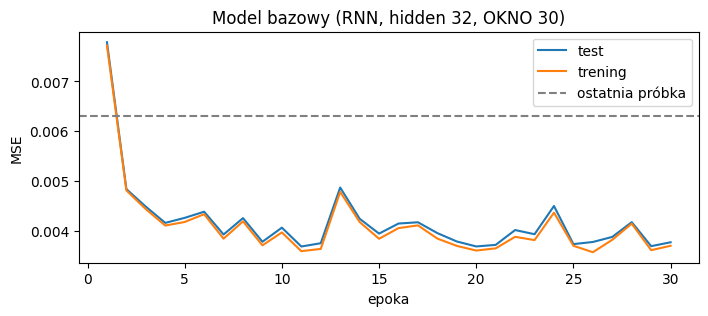

In [8]:
torch.manual_seed(0)
model_bazowy = ModelRNN(hidden=32, typ="RNN")
hist, hist_tr = trenuj(model_bazowy, Xtr, Ytr, Xte, Yte, epoki=30)
print(f"Model bazowy: test MSE {hist[0]:.4f} -> {hist[-1]:.4f} "
      f"(ostatnia epoka)")
print(f"Model bazowy: średnia z 5 ostatnich epok {np.mean(hist[-5:]):.5f}")
print(f"Heurystyka ostatnia próbka: {heurystyka(Xte, Yte):.5f}")
print(f"Prognoza = średnia z treningu: "
      f"{((Yte - Ytr.mean()) ** 2).mean().item():.5f}")

plt.figure(figsize=(8, 3))
plt.plot(range(1, 31), hist, label="test")
plt.plot(range(1, 31), hist_tr, label="trening")
plt.axhline(heurystyka(Xte, Yte), color="gray", ls="--",
            label="ostatnia próbka")
plt.title("Model bazowy (RNN, hidden 32, OKNO 30)")
plt.xlabel("epoka")
plt.ylabel("MSE")
plt.legend()
plt.show()

Tabela 1. Punkty odniesienia (OKNO 30)

| model | test MSE |
|---|---|
| heurystyka „ostatnia próbka” | 0,00631 |
| prognoza = średnia z treningu | 0,51725 |
| model bazowy RNN, hidden 32, ostatnia epoka (jak w notatniku) | 0,0038 |
| model bazowy RNN, hidden 32, średnia z 5 ostatnich epok | 0,00386 |

Wynik jest taki sam jak w oryginalnym notatniku (0,0078 → 0,0038)

Model bazowy ma MSE o ok. 39% niższe od heurystyki, czyli nie tylko kopiuje ostatnią próbkę

Strata treningowa i testowa idą prawie razem przez cały trening, krzywa ma skoki w 13. i 24. epoce

### 3.2 Eksperyment A, liczba jednostek (tabela 2, rys. 1)

GRU, OKNO 30

In [9]:
df_a = uruchom([(f"GRU, hidden={h}", "GRU", h, 30) for h in [8, 16, 32, 64]])
tabela(df_a)

,konfiguracja,parametry,test MSE,czas treningu [s]
0,heurystyka ostatnia próbka (OKNO=30),-,0.00631,-
1,"GRU, hidden=8",273,0.00380 ± 0.00004,3.0
2,"GRU, hidden=16",929,0.00374 ± 0.00002,3.2
3,"GRU, hidden=32",3393,0.00376 ± 0.00001,4.2
4,"GRU, hidden=64",12929,0.00375 ± 0.00008,5.7


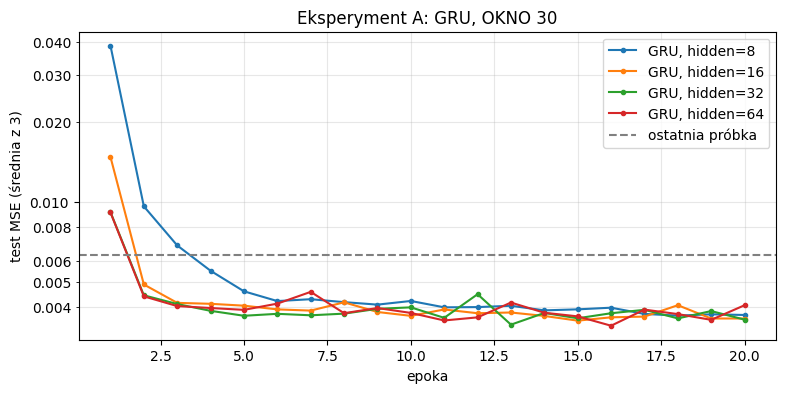

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
rysuj(df_a, ax, "Eksperyment A: GRU, OKNO 30")
_, _, Xte_30, Yte_30 = przygotuj(30)
ax.axhline(heurystyka(Xte_30, Yte_30), color="gray", ls="--",
           label="ostatnia próbka")
ax.legend()
plt.show()

Tabela 2. Eksperyment A, GRU, OKNO 30

| konfiguracja | parametry | test MSE | czas treningu [s] |
|---|---|---|---|
| heurystyka „ostatnia próbka” | - | 0,00631 | - |
| GRU, hidden 8 | 273 | 0,00380 ± 0,00004 | 3,0 |
| GRU, hidden 16 | 929 | 0,00374 ± 0,00002 | 3,2 |
| GRU, hidden 32 | 3 393 | 0,00376 ± 0,00001 | 4,2 |
| GRU, hidden 64 | 12 929 | 0,00375 ± 0,00008 | 5,7 |

Wszystkie cztery modele kończą prawie w tym samym miejscu (0,00374–0,00380), różnice są rzędu odchylenia między ziarnami

Hidden 8 na rys. 1 zaczyna dużo wyżej i do poziomu reszty schodzi dopiero po ok. 10 epokach, pozostałe już po 2–3 epokach

Hidden 64 ma 47 razy więcej parametrów niż hidden 8, trenuje się prawie 2 razy dłużej i ma największy rozrzut między ziarnami

### 3.3 Eksperyment B, długość okna (tabela 3, rys. 2)

GRU, hidden 32, przerywane linie to heurystyka dla danego okna w tym samym kolorze

In [11]:
df_b = uruchom([(f"GRU, OKNO={o}", "GRU", 32, o) for o in [10, 30, 60, 120]])
tabela(df_b)

,konfiguracja,parametry,test MSE,czas treningu [s]
0,heurystyka ostatnia próbka (OKNO=10),-,0.00628,-
1,heurystyka ostatnia próbka (OKNO=30),-,0.00631,-
2,heurystyka ostatnia próbka (OKNO=60),-,0.00633,-
3,heurystyka ostatnia próbka (OKNO=120),-,0.00631,-
4,"GRU, OKNO=10",3393,0.00414 ± 0.00019,1.7
5,"GRU, OKNO=30",3393,0.00376 ± 0.00001,3.6
6,"GRU, OKNO=60",3393,0.00343 ± 0.00021,6.9
7,"GRU, OKNO=120",3393,0.00344 ± 0.00019,13.9


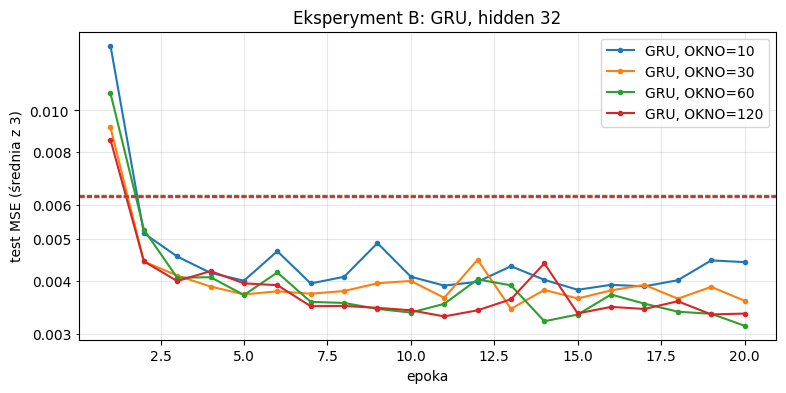

In [12]:
kolory = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
fig, ax = plt.subplots(figsize=(9, 4))
rysuj(df_b, ax, "Eksperyment B: GRU, hidden 32", kolory)
for okno, kolor in zip([10, 30, 60, 120], kolory):
    _, _, Xte_o, Yte_o = przygotuj(okno)
    ax.axhline(heurystyka(Xte_o, Yte_o), color=kolor, ls="--", lw=1)
ax.legend()
plt.show()

Tabela 3. Eksperyment B, GRU, hidden 32

| konfiguracja | parametry | test MSE | czas treningu [s] |
|---|---|---|---|
| heurystyka „ostatnia próbka”, OKNO 10 | - | 0,00628 | - |
| heurystyka „ostatnia próbka”, OKNO 30 | - | 0,00631 | - |
| heurystyka „ostatnia próbka”, OKNO 60 | - | 0,00633 | - |
| heurystyka „ostatnia próbka”, OKNO 120 | - | 0,00631 | - |
| GRU, OKNO 10 | 3 393 | 0,00414 ± 0,00019 | 1,7 |
| GRU, OKNO 30 | 3 393 | 0,00376 ± 0,00001 | 3,6 |
| GRU, OKNO 60 | 3 393 | 0,00343 ± 0,00021 | 6,9 |
| GRU, OKNO 120 | 3 393 | 0,00344 ± 0,00019 | 13,9 |

Najgorsze jest okno 10 (0,00414), okno 30 daje 0,00376, a okna 60 i 120 są najlepsze i praktycznie równe (0,00343 i 0,00344)

Krzywa dla okna 10 na rys. 2 jest najbardziej poszarpana i pod koniec lekko rośnie

Liczba parametrów się nie zmienia, ale czas treningu rośnie mniej więcej proporcjonalnie do długości okna, bo sieć przechodzi przez więcej kroków

Każde okno daje trochę inną liczbę przykładów (od 1592/398 przy oknie 10 do 1504/376 przy oknie 120), ale heurystyka wychodzi prawie tak samo (0,00628–0,00633), więc zbiory testowe są porównywalne

### 3.4 Eksperyment C, typ komórki (tabela 4, rys. 3)

hidden 32, OKNO 10 i 120

In [13]:
df_c = uruchom([(f"{typ}, OKNO={o}", typ, 32, o)
                for o in [10, 120] for typ in ["RNN", "LSTM", "GRU"]])
tabela(df_c)

,konfiguracja,parametry,test MSE,czas treningu [s]
0,heurystyka ostatnia próbka (OKNO=10),-,0.00628,-
1,heurystyka ostatnia próbka (OKNO=120),-,0.00631,-
2,"RNN, OKNO=10",1153,0.00417 ± 0.00025,0.8
3,"LSTM, OKNO=10",4513,0.00415 ± 0.00011,1.0
4,"GRU, OKNO=10",3393,0.00414 ± 0.00019,1.6
5,"RNN, OKNO=120",1153,0.00400 ± 0.00001,5.0
6,"LSTM, OKNO=120",4513,0.00375 ± 0.00013,4.1
7,"GRU, OKNO=120",3393,0.00344 ± 0.00019,14.4


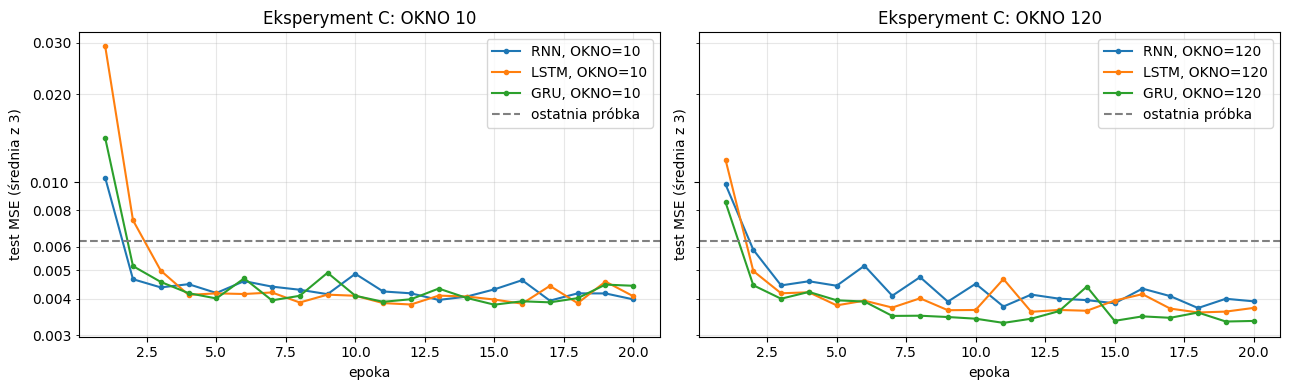

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, okno in zip(axes, [10, 120]):
    rysuj(df_c[df_c["okno"] == okno], ax, f"Eksperyment C: OKNO {okno}")
    _, _, Xte_o, Yte_o = przygotuj(okno)
    ax.axhline(heurystyka(Xte_o, Yte_o), color="gray", ls="--",
               label="ostatnia próbka")
    ax.legend()
plt.tight_layout()
plt.show()

Tabela 4. Eksperyment C, hidden 32

| konfiguracja | parametry | test MSE | czas treningu [s] |
|---|---|---|---|
| heurystyka „ostatnia próbka”, OKNO 10 | - | 0,00628 | - |
| heurystyka „ostatnia próbka”, OKNO 120 | - | 0,00631 | - |
| RNN, OKNO 10 | 1 153 | 0,00417 ± 0,00025 | 0,8 |
| LSTM, OKNO 10 | 4 513 | 0,00415 ± 0,00011 | 1,0 |
| GRU, OKNO 10 | 3 393 | 0,00414 ± 0,00019 | 1,6 |
| RNN, OKNO 120 | 1 153 | 0,00400 ± 0,00001 | 5,0 |
| LSTM, OKNO 120 | 4 513 | 0,00375 ± 0,00013 | 4,1 |
| GRU, OKNO 120 | 3 393 | 0,00344 ± 0,00019 | 14,4 |

Przy oknie 10 wszystkie trzy komórki dają to samo (0,00414–0,00417)

Przy oknie 120 widać kolejność: GRU 0,00344, LSTM 0,00375, RNN 0,00400

Po wydłużeniu okna z 10 do 120 GRU poprawił się o 0,00070, LSTM o 0,00040, a RNN tylko o 0,00017

LSTM i GRU mają 3–4 razy więcej parametrów niż RNN, więc to nie są modele tej samej wielkości

Czasy są z CPU, GRU przy oknie 120 trenował się najdłużej mimo mniejszej liczby parametrów niż LSTM, to zależy od implementacji i sprzętu, na GPU może wyjść inaczej

### 3.5 Najlepsza konfiguracja (rys. 4 i 5)

Najlepsza to ta z najniższą średnią test MSE ze wszystkich trzech eksperymentów

                  srednia  odchylenie
typ  hidden okno                     
GRU  32     60    0.00343     0.00021
            120   0.00344     0.00019
     16     30    0.00374     0.00002
LSTM 32     120   0.00375     0.00013
GRU  64     30    0.00375     0.00008

Najlepsza: GRU, hidden=32, OKNO=60


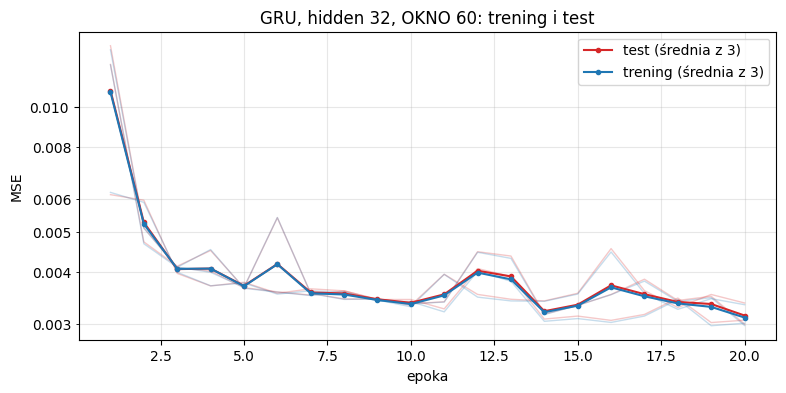

In [15]:
wszystkie = pd.concat([df_a, df_b, df_c], ignore_index=True)
ranking = (wszystkie.groupby(["typ", "hidden", "okno"])["mse"]
           .agg(srednia="mean", odchylenie=lambda s: s.std(ddof=0))
           .sort_values("srednia"))
print(ranking.head(5).round(5).to_string())
typ_b, hidden_b, okno_b = ranking.index[0]
najlepsza = wszystkie[(wszystkie["typ"] == typ_b)
                      & (wszystkie["hidden"] == hidden_b)
                      & (wszystkie["okno"] == okno_b)
                      ].drop_duplicates("ziarno")
print(f"\nNajlepsza: {typ_b}, hidden={hidden_b}, OKNO={okno_b}")

ep = range(1, EPOKI + 1)
fig, ax = plt.subplots(figsize=(9, 4))
for _, r in najlepsza.iterrows():
    ax.plot(ep, r["hist"], color="tab:red", alpha=0.25, lw=1)
    ax.plot(ep, r["hist_tr"], color="tab:blue", alpha=0.25, lw=1)
ax.plot(ep, np.mean(najlepsza["hist"].to_list(), axis=0), color="tab:red",
        marker="o", ms=3, label="test (średnia z 3)")
ax.plot(ep, np.mean(najlepsza["hist_tr"].to_list(), axis=0),
        color="tab:blue", marker="o", ms=3, label="trening (średnia z 3)")
ax.set(title=f"{typ_b}, hidden {hidden_b}, OKNO {okno_b}: trening i test",
       xlabel="epoka", ylabel="MSE", yscale="log")
osie_log(ax)
ax.legend()
plt.show()

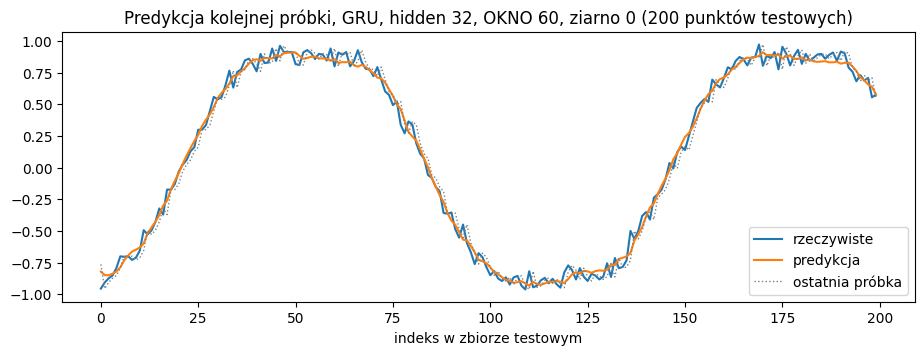

MSE na tych 200 punktach: 0.00328


In [16]:
_, _, Xte_b, Yte_b = przygotuj(okno_b)
model_b = najlepsza[najlepsza["ziarno"] == 0]["model"].iloc[0].eval()
with torch.no_grad():
    pred = model_b(Xte_b).cpu().numpy().ravel()
prawdziwe = Yte_b.cpu().numpy().ravel()
ostatnia = Xte_b[:, -1, 0].cpu().numpy()

plt.figure(figsize=(11, 3.5))
plt.plot(prawdziwe[:200], label="rzeczywiste", lw=1.5)
plt.plot(pred[:200], label="predykcja", lw=1.5)
plt.plot(ostatnia[:200], label="ostatnia próbka", lw=1, ls=":",
         color="gray")
plt.title(f"Predykcja kolejnej próbki, {typ_b}, hidden {hidden_b}, "
          f"OKNO {okno_b}, ziarno 0 (200 punktów testowych)")
plt.xlabel("indeks w zbiorze testowym")
plt.legend()
plt.show()
mse200 = np.mean((pred[:200] - prawdziwe[:200]) ** 2)
print(f"MSE na tych 200 punktach: {mse200:.5f}")

Najlepsza jest konfiguracja GRU, hidden 32, OKNO 60: 0,00343 ± 0,00021, tuż za nią GRU z oknem 120 (0,00344 ± 0,00019), różnica jest dużo mniejsza od odchylenia

Rys. 4: strata treningowa i testowa prawie się pokrywają, w 20. epoce strata dalej lekko spada, w pojedynczych przebiegach są skoki ok. 6., 12.–13. i 16. epoki

Rys. 5: predykcja idzie po sygnale i przechodzi przez środek szumu, nie jest przesunięta o jeden krok w prawo jak heurystyka (kropkowana linia), MSE na tych 200 punktach to 0,00328

## 4. Analiza i interpretacja

### 4.1 Hipotezy (przed uruchomieniem)

- eksperyment A: myślę, że od hidden 8 do 32 MSE trochę spadnie, a 64 już nic nie da, bo sygnał to dwie sinusoidy z szumem i nie trzeba dużej pojemności, przy lr 1e-2 większy model może się uczyć mniej stabilnie
- eksperyment B: myślę, że najgorsze będzie okno 10, bo z kilku zaszumionych próbek trudno ocenić fazę i kierunek sygnału, najlepsze będzie 30 albo 60, a 120 (prawie cały okres) już nie poprawi wyniku, bo trening jest trudniejszy i okien jest mniej
- eksperyment C: myślę, że przy oknie 120 RNN wypadnie wyraźnie gorzej od LSTM i GRU przez zanikanie gradientu, a przy oknie 10 różnice będą małe

### 4.2 Obserwacje

Liczba jednostek (rys. 1, tabela 2)
- nawet GRU z 8 jednostkami (273 parametry) osiąga prawie ten sam wynik co z 64 (12 929 parametrów)
- mały model potrzebuje tylko kilku epok więcej na start, potem dochodzi do tego samego poziomu
- sygnał to dwie sinusoidy z szumem, więc do jego opisania wystarcza mała pojemność, większy model nic nie dokłada, a trenuje się dłużej

Długość okna (rys. 2, tabela 3)
- dłuższe okno pomaga do 60 próbek, czyli mniej więcej pół okresu głównej sinusoidy (126 próbek)
- z 10 zaszumionych próbek trudno ocenić, w którym miejscu okresu jest sygnał i w którą stronę idzie, dlatego okno 10 jest najsłabsze i najmniej stabilne
- okno 120 nie daje już poprawy, prawdopodobnie dlatego, że pół okresu wystarcza do ustalenia fazy, a dalsze próbki dokładają głównie długość treningu

Typ komórki (rys. 3, tabela 4)
- przy krótkim oknie typ komórki nie ma znaczenia
- przy oknie 120 zwykły RNN zyskuje najmniej, co pasuje do zanikania gradientu przy długim łańcuchu kroków, a GRU i LSTM dzięki bramkom lepiej korzystają z dłuższego kontekstu
- z eksperymentu A wiadomo, że sama liczba parametrów nic nie zmienia, więc przewaga GRU i LSTM przy oknie 120 wynika raczej z bramek niż z większego rozmiaru

Heurystyka i jakość uczenia
- wszystkie modele są lepsze od heurystyki o 34–46% (0,0034–0,0042 wobec ok. 0,0063)
- najlepszy wynik (0,00343) jest już blisko granicy szumu 0,0025 (wariancja szumu 0,05²), poniżej której nie da się zejść
- w żadnym przebiegu nie było przeuczenia: strata treningowa i testowa idą razem, bo zbiór testowy to dalszy ciąg tego samego okresowego sygnału
- nie było nan ani wybuchu gradientu, ale krzywe są poszarpane przez lr 1e-2, najbardziej przy oknie 10 i dla RNN
- przy oknie 60 strata wciąż spada w ostatnich epokach, więc ten model jest lekko niedotrenowany

### 4.3 Czy hipotezy się potwierdziły

- A tylko częściowo: hidden 64 rzeczywiście nic nie dał, ale między 8 a 32 też prawie nie ma różnicy, liczba jednostek wpływa głównie na szybkość uczenia na początku
- B tak: najgorsze okno 10, najlepsze 60, a 120 nie poprawiło już wyniku
- C tak: przy oknie 120 RNN jest wyraźnie gorszy od LSTM i GRU, przy oknie 10 różnic nie ma

## 5. Wnioski

- większa liczba jednostek nie poprawia wyniku: GRU z 8 i z 64 jednostkami kończy na prawie tym samym MSE (0,00380 i 0,00375), więcej jednostek to tylko dłuższy trening
- najlepsze jest okno 60 (0,00343), okno 120 daje to samo, a okno 10 jest najgorsze, bo dłuższe okno pozwala uśrednić szum i rozpoznać fazę sygnału, a od ok. pół okresu nowych informacji już nie przybywa
- RNN i GRU/LSTM nie reagują tak samo: przy oknie 10 są równe, a przy 120 GRU poprawia się 4 razy bardziej niż RNN, bo zwykły RNN gorzej przenosi informację przez długi ciąg kroków
- modele są wyraźnie lepsze od heurystyki „ostatnia próbka”: 0,0034–0,0042 wobec 0,0063, a najlepszy jest niedaleko granicy szumu 0,0025
- nie było przeuczenia ani niestabilności typu nan, krzywe są tylko poszarpane przez lr 1e-2, a model z oknem 60 jest po 20 epokach lekko niedotrenowany
- hipotezy B i C się potwierdziły, A tylko częściowo, bo nawet bardzo mały model wystarcza
- do poprawy: więcej epok albo zmniejszanie lr pod koniec treningu, żeby wygładzić krzywe, i więcej ziaren, żeby lepiej oddzielić małe różnice od losowości